# Setup

TDL : 
- Standardize Demographics plots (Barplot for each subplot with age category bins)

In [44]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Setting up palette for plots
palette = sns.color_palette("bright")
sns.set_palette(palette)

# Labels above barplots
def label_bars(ax, fmt="%.1f%%"):
    for c in ax.containers:
        ax.bar_label(c, fmt=fmt)

### Preliminary Data Structure

In [2]:
# Loading the dataset
data = pd.read_csv("loans.csv",sep = ",")
data.shape 

(5000, 14)

The dataset has 5000 rows and 14 columns, as expected.

In [3]:
# Preview of the data
data.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


The dataset was imported correctly and contains no text-valued variables. Let's now take a closer look at the data types.

In [4]:
# Technical summary of the dataset
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


Although all columns are stored as numeric data types (`int64` and `float64`), several variables are binary (`Personal Loan`, `Securities Account`, etc.) or ordinal categorical variables (`Education`) represented numerically. We will decide whether to correctly recode them or not. 

In [7]:
# Checking if there is any missing values
data.isna().sum()

ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

The check shows that there are no missing values in any of the variables, so no missing-value treatment or in-depth data cleaning is required for the following analysis.

In [8]:
# Checking if the identifier is unique
data["ID"].nunique()

5000

The dataset contains 5,000 observations and 5,000 unique IDs, indicating that each ID corresponds to a single observation. We therefore do not need to aggregate observations. Let's also check for duplicated rows.

In [9]:
# Removing any duplicated rows
data = data.drop_duplicates()
data.shape 

(5000, 14)

No duplicated rows were found, so no deduplication is necessary. The preliminary checks show that the dataset is ready for exploratory analysis, although some variables may need to be recasted.

### Exploratory Data Analysis

In [10]:
# Descriptive statistics
data.describe().T
# print(data.describe().T.to_markdown()) # Descriptive statistics table for the report

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIP Code,5000.0,93152.503000,2121.852197,9307.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


The dataset does not show any obvious extreme values based on the descriptive statistics. However, negative values are found in the `Experience` variable, so there observations need to be further investigated.

In [5]:
# Investigating negative experience observations
data_negative_exp = data[data["Experience"] < 0]
data_negative_exp.describe().T
# print(data_negative_exp.describe().T.to_markdown()) # Descriptive statistics table for the report

,count,mean,std,min,25%,50%,75%,max
ID,52.0,2427.346154,1478.834118,90.0,767.25,2783.5,3669.500,4958.0
Age,52.0,24.519231,1.475159,23.0,24.00,24.0,25.000,29.0
Experience,52.0,-1.442308,0.639039,-3.0,-2.00,-1.0,-1.000,-1.0
Income,52.0,69.942308,37.955295,12.0,40.75,65.5,86.750,150.0
ZIP Code,52.0,93240.961538,1611.654806,90065.0,92167.75,93060.0,94720.000,95842.0
Family,52.0,2.865385,0.970725,1.0,2.00,3.0,4.000,4.0
CCAvg,52.0,2.129423,1.750562,0.2,1.00,1.8,2.325,7.2
Education,52.0,2.076923,0.836570,1.0,1.00,2.0,3.000,3.0
Mortgage,52.0,43.596154,90.027068,0.0,0.00,0.0,0.000,314.0
Personal Loan,52.0,0.000000,0.000000,0.0,0.00,0.0,0.000,0.0


There are 52 observations with negative experience, representing 1.04% of the entire dataset. These observations involve relatively young customers, aged between 23 and 29, whom generally have lower incomes than the full sample. This may indicate data-entry errors or a deliberate coding convention.

### Recasting and cleaning variables

In [6]:
data[["Age", "Experience"]].corr()
data[["Experience", "Personal Loan"]].corr()

,Experience,Personal Loan
Experience,1.000000,-0.007413
Personal Loan,-0.007413,1.000000


`Age` and `Experience` are almost perfectly correlated (correlation of 0.99), such that experience is almost a deterministic function of Age. Moreover, it has little to no correlation with the target variable `Personal Loan`. Since it carries no extra information and seemingly suffers from badly encoded values (52 negative values as spotted above), we decide to drop `Experience` instead of trying to fix it.

In [13]:
data_zip = data.copy() # Creating a copy
data_zip["ZIP Code"] = data_zip["ZIP Code"].astype(str) # Converting ZIP Code into a string type

print(data_zip["ZIP Code"].str.len().value_counts())
print(data_zip[data_zip["ZIP Code"].str.len() == 4]) # Displaying the 4-digits ZIP Code observation

# Checking if the ZIP Code provides useful information for the target variable
data_zip["ZIP 3"] = data_zip["ZIP Code"].str[:3] # 3-digits ZIP Code
data_zip["ZIP 3"].value_counts(normalize=True) * 100 # Distribution of groups at the 3-digits level
data_zip.groupby("ZIP 3")["Personal Loan"].mean() * 100 # Conversion rate at the 3-digits level

data_zip["ZIP 2"] = data_zip["ZIP Code"].str[:2] # 2-digits ZIP Code
print(data_zip["ZIP 2"].value_counts(normalize=True) * 100) # Distribution of groups at the 2-digits level
print(data_zip.groupby("ZIP 2")["Personal Loan"].mean() * 100) # Conversion rate at the 2-digits level

ZIP Code
5    4999
4       1
Name: count, dtype: int64
      ID  Age  Experience  Income ZIP Code  Family  CCAvg  Education  \
384  385   51          25      21     9307       4    0.6          3   

     Mortgage  Personal Loan  Securities Account  CD Account  Online  \
384         0              0                   0           0       1   

     CreditCard  
384           1  
ZIP 2
94    29.44
92    19.76
95    16.30
90    14.06
91    11.30
93     8.34
96     0.80
Name: proportion, dtype: float64
ZIP 2
90     9.530583
91     9.734513
92     9.514170
93    10.311751
94     9.375000
95     9.815951
96     7.500000
Name: Personal Loan, dtype: float64


For `ZIP Code`, we notice that one entry is badly encoded with only a 4-digits ZIP Code instead of 5 for the rest of the dataset. We observe that the conversion rate seems roughly constant (between 9.4% to 10.3%, except for one small group with only 0.8% of the customers) at the 2-digits level. We conclude that location is uninformative for loan acceptance and we leave this variable aside for the rest of the analysis.

In [7]:
# Renaming variables for clarity
data = data.rename(columns={
    "CreditCard": "Credit Card",
    "Online": "Online Facilities",
    "CD Account": "Deposit Account",
})

### Question 1: What is the conversion rate (percentage of clients that contracted a personal loan) of the marketing campaign?

In [14]:
# Normalized Value Counts of the Loan Variable 
data["Personal Loan"].value_counts(normalize=True) * 100

Personal Loan
0    90.4
1     9.6
Name: proportion, dtype: float64

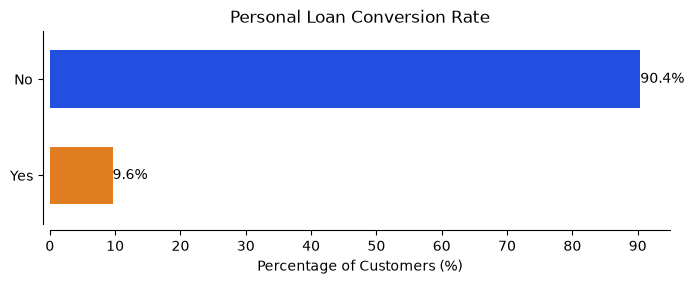

In [15]:
fig, ax = plt.subplots(figsize=(8, 2.5))

sns.countplot(
    data=data,
    y="Personal Loan",
    hue="Personal Loan",
    order=[0, 1],
    stat="percent",
    width=0.6,
    legend=False,
    ax=ax,
)

label_bars(ax)

ax.set(
    title="Personal Loan Conversion Rate",
    xlabel="Percentage of Customers (%)",
    ylabel=None,
    xticks=np.arange(0, 100, 10),
    yticks=[0, 1],
    yticklabels=["No", "Yes"],
)

sns.despine(offset=5)

# Saving the figure for the report
plt.savefig("figures/q1.svg")
plt.show()

Given that each identifier is unique, only 480 out of 5000 clients contracted a personal loan, corresponding to a campaign conversion rate of 9.6%. This class imbalance is pretty important for the rest of the analysis, since it means that a naive model always predicting "No" will achieve an accuracy of 90.4%. Therefore, accuracy might be a misleading metric when evaluating our classifiers.

### Question 2: How are the different variables (age, income, education, etc.) distributed in the dataset?


#### Distribution of Customers Profile (Age, Education, Family Size)

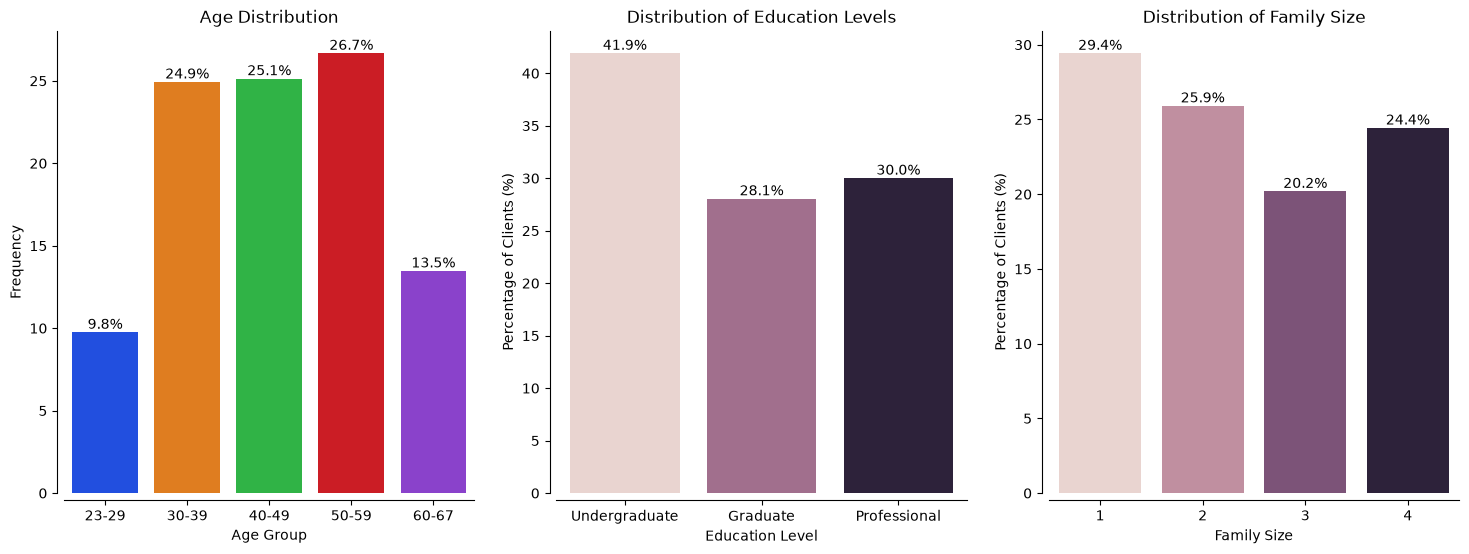

In [29]:
# Decadal age categories for simpler visualization
age_groups = pd.cut(
    data["Age"],
    bins=[20, 29, 39, 49, 59, 70],
    labels=["23-29", "30-39", "40-49", "50-59", "60-67"],
)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Left plot: Age Distribution
sns.countplot(
    x=age_groups,
    hue=age_groups,
    stat="percent", 
    dodge=False,
    legend=False,
    ax=axes[0]
)
label_bars(axes[0])
axes[0].set(
    title="Age Distribution",
    xlabel="Age Group",
    ylabel="Frequency",
)

# 2. Middle plot: Education Levels
sns.countplot(
    data=data,
    x="Education",
    hue="Education",
    order=[1, 2, 3],
    stat="percent",
    legend=False,
    ax=axes[1],
)
label_bars(axes[1])
axes[1].set(
    title="Distribution of Education Levels",
    xlabel="Education Level",
    ylabel="Percentage of Clients (%)",
    xticks=[0, 1, 2],
    xticklabels=["Undergraduate", "Graduate", "Professional"],
)

# 2. Right plot: Family Size
sns.countplot(
    data=data,
    x="Family",
    hue="Family",
    stat="percent",
    legend=False,
    ax=axes[2],
)
label_bars(axes[2])
axes[2].set(
    title="Distribution of Family Size",
    xlabel="Family Size",
    ylabel="Percentage of Clients (%)",
)

sns.despine(offset=5)

# Saving the figure for the report
plt.savefig("figures/q2a.svg")
plt.show()

**Interpretation** : The customer base is heavily concentrated in middle-aged brackets: clients aged 30-59 make up 76.7% of the dataset, spread almost evenly across age groups. Undergraduate form the largest group, as well as one person households. 

#### Distribution of Financial Variables (Income, Credit Card Spendings, Mortgage)

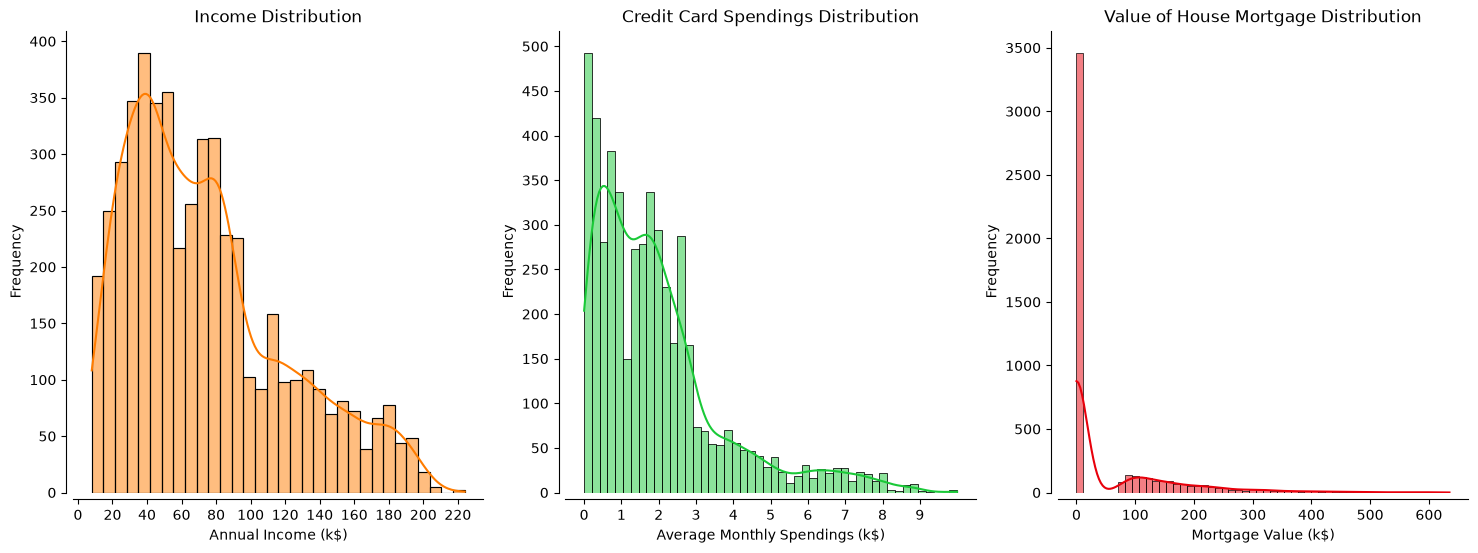

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18,6))

# 1. Left plot: Income Distribution
sns.histplot(
    data["Income"],
    kde=True,
    color=palette[1],
    ax=axes[0]
)
axes[0].set(
    title="Income Distribution",
    xlabel="Annual Income (k$)",
    ylabel="Frequency",
    xticks=np.arange(0, data["Income"].max(), 20),
)

# 2. Middle plot: Average monthly spendings on credit card (in $k)
sns.histplot(
    data["CCAvg"],
    kde=True,
    color=palette[2],
    ax=axes[1]
)
axes[1].set(
    title="Credit Card Spendings Distribution",
    xlabel="Average Monthly Spendings (k$)",
    ylabel="Frequency",
    xticks=np.arange(0, data["CCAvg"].max()),
    yticks=np.arange(0, 501, 50)
)

# 3. Right plot: Value of house mortgage (in $k)
sns.histplot(
    data["Mortgage"],
    kde=True,
    color=palette[3],
    ax=axes[2]
)
axes[2].set(
    title="Value of House Mortgage Distribution",
    xlabel="Mortgage Value (k$)",
    ylabel="Frequency",
    xticks=np.arange(0, data["Mortgage"].max(), 100)
)

sns.despine(offset=5)

# Saving the figure for the report
plt.savefig("figures/q2b.svg")
plt.show()

**Interpretation**: 69,24% customers have no mortgage at all, while only 2,12% have zero monthly credit card spending. The three variables are right skewed, thus justifying the use of Spearman correlations and non-parametric tests (Mann-Whitney).

#### Distribution of Banking Products (Loan, Securities Account, CD Account, Online and Credit Card)

To facilitate the comparison of all five binary variables on a single plot, we first calculate the percentage distribution for each banking products before reshaping the data into long-format (required to display multiple variables on the same axes). 

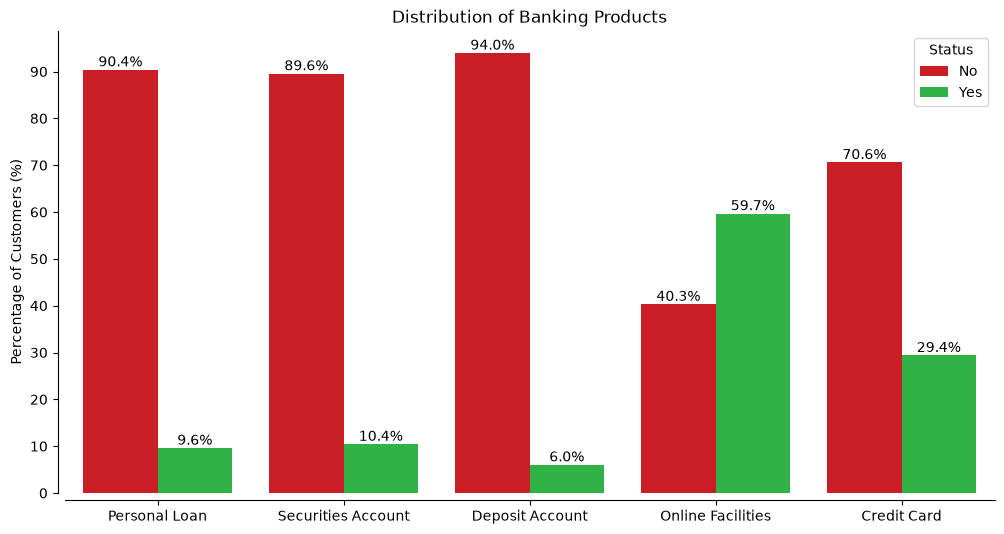

In [31]:
# Defining binary variables
binary_cols = ["Personal Loan", "Securities Account", "Deposit Account", "Online Facilities", "Credit Card"]

# Compute percentages of each category
yes_pct = data[binary_cols].mean() * 100
pct_df = (
    pd.DataFrame({"No": 100 - yes_pct, "Yes": yes_pct})
    .reset_index(names="Variable")
    .melt(id_vars="Variable", var_name="Status", value_name="Percent")
)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=pct_df,
    x="Variable",
    y="Percent",
    hue="Status",
    palette={"No": palette[3], "Yes": palette[2]},
    ax=ax)

label_bars(ax)

ax.set(
    title="Distribution of Banking Products",
    xlabel=None,
    ylabel="Percentage of Customers (%)",
    yticks=np.arange(0, 100, 10) #[]
)

sns.despine(offset=5) # left=True

# Saving the figure for the report
plt.savefig("figures/q2c.svg")
plt.show()

**Interpretation**: Most banking products in the dataset are held by only a small fraction of customers, roughly 90% or more do not hold Personal Loans, Securities Accounts or Deposit Account. Credit Cards are more common with an adoption rate of 29.4%, while Online Banking is by far the most widely used service with 59.7% of customers enrolled.

### Question 3: How do the different variables interact with each other?


#### Correlation Matrix

We first compute a correlation matrix to inspect how customers features potentially interact together. Since the dataset mixes binary, ordinal and skewed continuous variables, we use Spearman correlation.

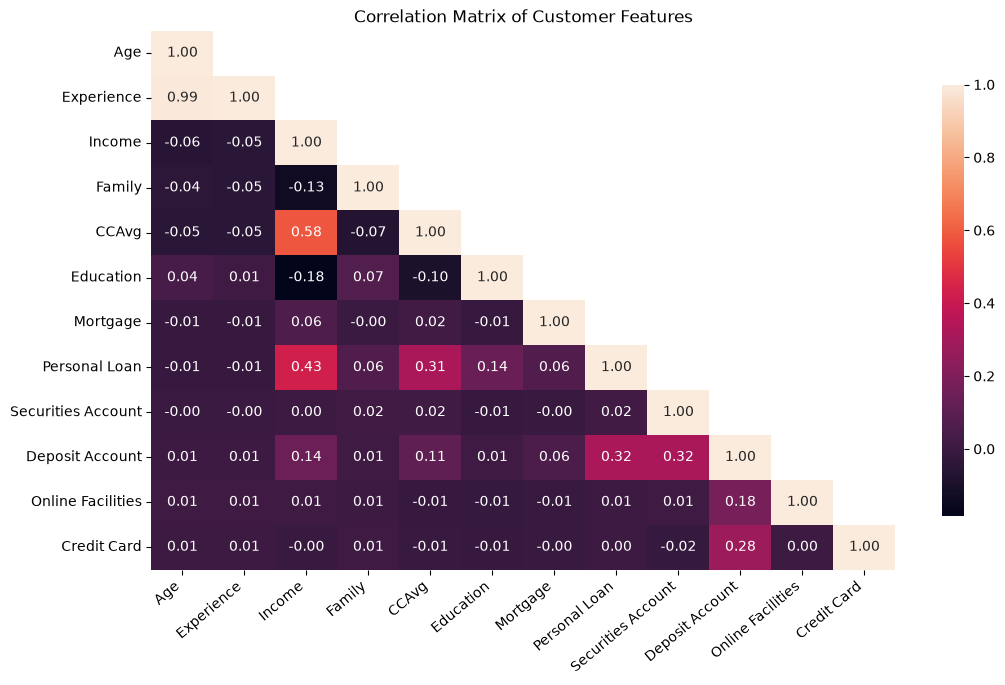

In [ ]:
# Exclude non-informative identifier columns
df_corr = data.drop(columns=["ID", "ZIP Code"]).copy()
corr = df_corr.corr(method="spearman")

# Hiding the upper triangle for clarity
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# Plot
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    corr, 
    mask=mask,
    annot= True,
    fmt=".2f",
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set(title="Correlation Matrix of Customer Features")
plt.xticks(rotation=40, ha="right")

# Saving the figure for the report
plt.savefig("figures/q3a.svg", bbox_inches="tight")
plt.show()

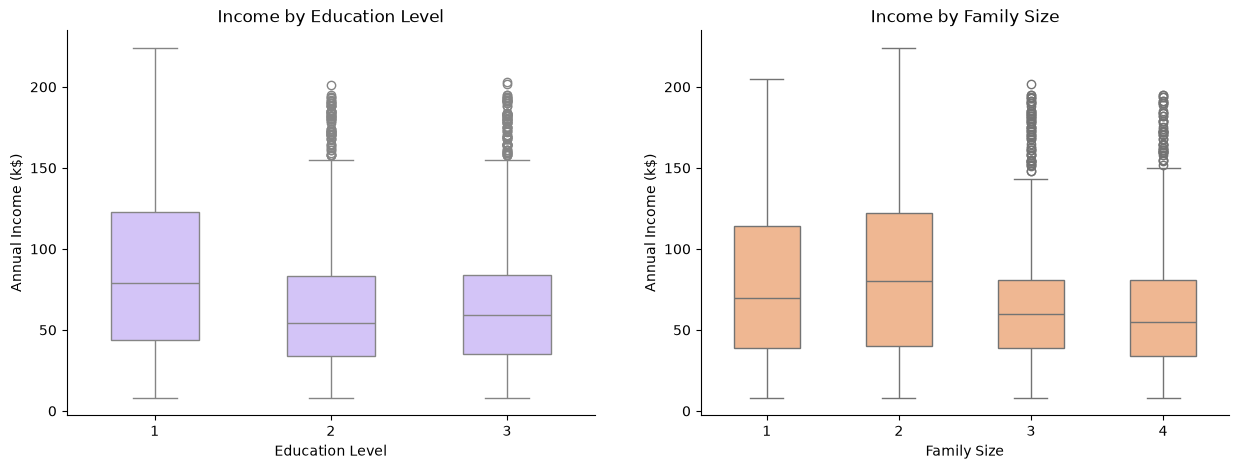

In [158]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=data, x="Education", y="Income",
            color=pastel[4], width=0.5, ax=axes[0])
axes[0].set(title="Income by Education Level", xlabel="Education Level", ylabel="Annual Income (k$)")
sns.boxplot(data=data, x="Family", y="Income", color=pastel[1], width=0.5, ax=axes[1])
axes[1].set(title="Income by Family Size", xlabel="Family Size", ylabel="Annual Income (k$)")
sns.despine()


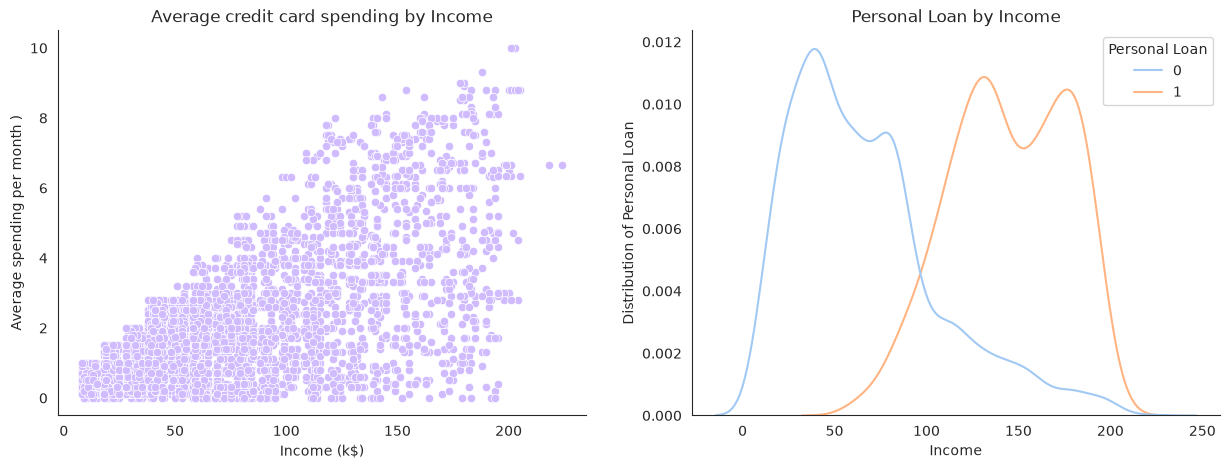

In [212]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=data, x="Income", y="CCAvg",
            color=pastel[4], ax=axes[0])
axes[0].set(title="Average credit card spending by Income", xlabel="Income (k$)", ylabel="Average spending per month )")
sns.kdeplot(data=data, x="Income", hue="Personal Loan", color=pastel[1],  ax=axes[1], common_norm=False)
axes[1].set(title="Personal Loan by Income", xlabel="Income", ylabel="Distribution of Personal Loan")
sns.despine()

In [213]:
# The above graph suggests an investigation within the high income customers.
high = data[data["Income"] > 100]

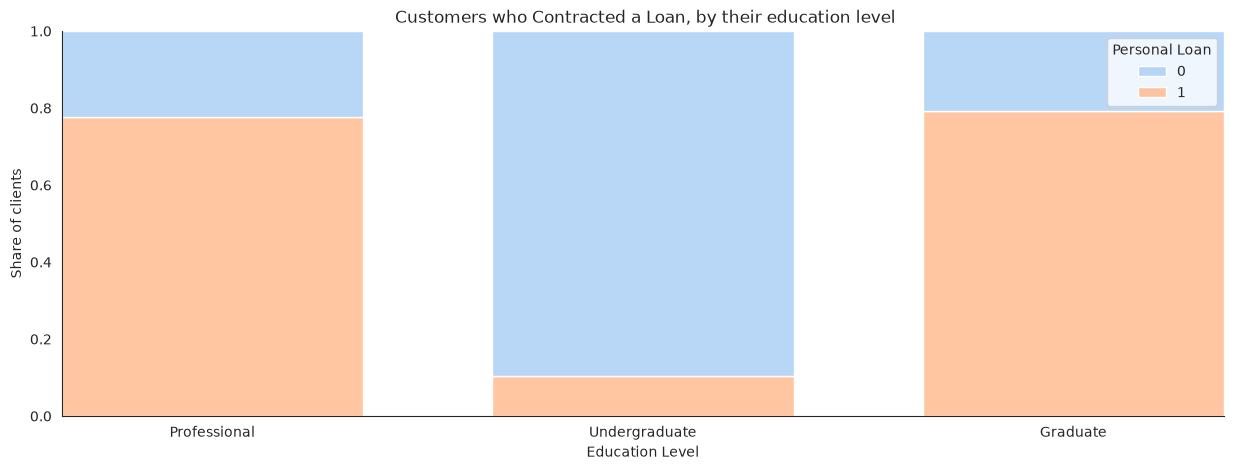

In [214]:
fig, ax = plt.subplots(1, figsize=(15, 5))
sns.histplot(data=high, x="Education_Label", hue="Personal Loan",
            color=pastel[4], ax = ax, common_norm="False",  stat = "proportion", hue_order = [0,1], multiple = "fill", shrink = 0.7)
ax.set(title=" Customers who Contracted a Loan, by their education level", xlabel="Education Level", ylabel="Share of clients")
sns.despine()

### Question 4: Are age, income, education, etc. distributed similarly for customers who have security accounts and those who don't?

We first proceed by computing the Mann-Whitney U test for continuous variable to test whether the customers with or without security accounts have the same underlying distribution or not. Second we compute the chi-squared test of independence for categorical variables. 

In [53]:
yes = data[data["Securities Account"] == 1] 
no = data[data["Securities Account"] == 0]

# Continuous variables: Mann-Whitney U test
print("Age:", stats.mannwhitneyu(yes["Age"], no["Age"]))
print("Income:", stats.mannwhitneyu(yes["Income"], no["Income"]))
print("CCAvg:", stats.mannwhitneyu(yes["CCAvg"], no["CCAvg"]))
print("Mortgage:", stats.mannwhitneyu(yes["Mortgage"], no["Mortgage"]))

# Categorical variables: Chi-squared test
print("Education:", stats.chi2_contingency(pd.crosstab(data["Education"], data["Securities Account"])))
print("Family:", stats.chi2_contingency(pd.crosstab(data["Family"], data["Securities Account"])))
print("Online Facilities:", stats.chi2_contingency(pd.crosstab(data["Online Facilities"], data["Securities Account"])))
print("Credit Card:", stats.chi2_contingency(pd.crosstab(data["Credit Card"], data["Securities Account"])))

Age: MannwhitneyuResult(statistic=np.float64(1168227.0), pvalue=np.float64(0.9864349068389239))
Income: MannwhitneyuResult(statistic=np.float64(1177543.5), pvalue=np.float64(0.7783411374480849))
CCAvg: MannwhitneyuResult(statistic=np.float64(1210692.0), pvalue=np.float64(0.17892383853634275))
Mortgage: MannwhitneyuResult(statistic=np.float64(1161748.5), pvalue=np.float64(0.7835089335493282))
Education: Chi2ContingencyResult(statistic=np.float64(0.7714682435445044), pvalue=np.float64(0.6799512858920017), dof=2, expected_freq=array([[1877.1776,  218.8224],
       [1256.5268,  146.4732],
       [1344.2956,  156.7044]]))
Family: Chi2ContingencyResult(statistic=np.float64(2.13675190436645), pvalue=np.float64(0.5445134585195501), dof=3, expected_freq=array([[1318.3232,  153.6768],
       [1160.6976,  135.3024],
       [ 904.556 ,  105.444 ],
       [1094.4232,  127.5768]]))
Online Facilities: Chi2ContingencyResult(statistic=np.float64(0.7153024169236211), pvalue=np.float64(0.3976891379898248

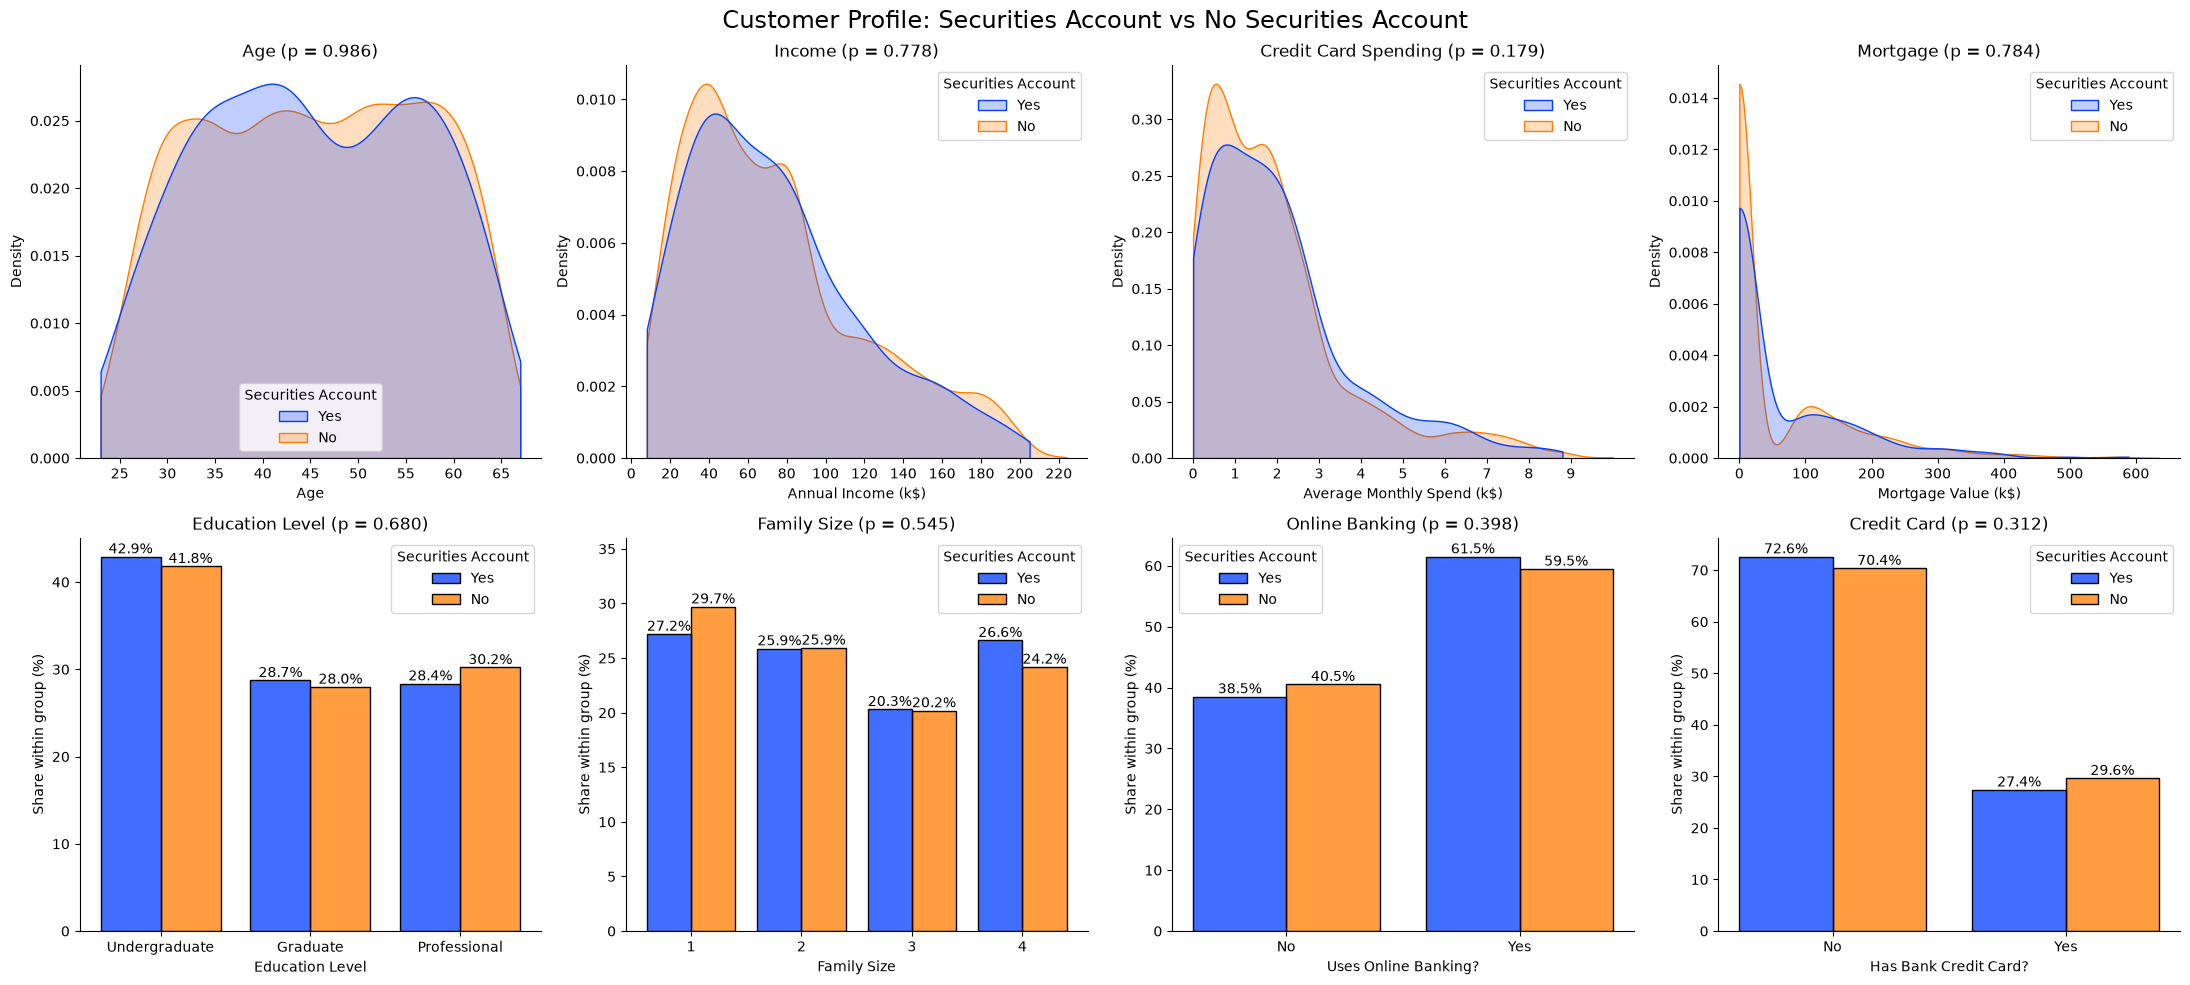

In [60]:
# Dataplot
data_plot = data.copy()
data_plot["Securities Account"] = data_plot["Securities Account"].map({0:"No", 1:"Yes"})
data_plot["Online Facilities"] = data_plot["Online Facilities"].map({0:"No", 1:"Yes"})
data_plot["Credit Card"] = data_plot["Credit Card"].map({0:"No", 1:"Yes"})
data_plot["Deposit Account"] = data_plot["Deposit Account"].map({0:"No", 1:"Yes"})

# Panel plot (2x4)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

# Row 1: Continuous variables
## Plot 1: Age
sns.kdeplot(
    data=data_plot,
    x="Age",
    hue="Securities Account",
    fill=True,
    common_norm=False,
    cut=0,
    ax=axes[0]
)
axes[0].set(
    title="Age (p = 0.986)",
    xlabel="Age",
    ylabel="Density",
    xticks=np.arange(25, data["Age"].max(), 5)
)

## Plot 2: Income
sns.kdeplot(
    data=data_plot,
    x="Income",
    hue="Securities Account",
    fill=True,
    common_norm=False,
    cut=0,
    ax=axes[1]
)
axes[1].set(
    title="Income (p = 0.778)",
    xlabel="Annual Income (k$)",
    ylabel="Density",
    xticks=np.arange(0, data["Income"].max(), 20)
)

## Plot 3: Average Credit Card Spending
sns.kdeplot(
    data=data_plot,
    x="CCAvg",
    hue="Securities Account",
    fill=True,
    common_norm=False,
    cut=0,
    ax=axes[2],
)
axes[2].set(
    title='Credit Card Spending (p = 0.179)',
    xlabel='Average Monthly Spend (k$)',
    ylabel='Density',
    xticks=np.arange(0, data["CCAvg"].max()),
)

## Plot 4: House Mortgage Value
sns.kdeplot(
    data=data_plot,
    x="Mortgage",
    hue="Securities Account",
    fill=True,
    common_norm=False,
    cut=0,
    ax=axes[3],
)
axes[3].set(
    title="Mortgage (p = 0.784)",
    xlabel="Mortgage Value (k$)",
    ylabel="Density",
    xticks=np.arange(0, data["Mortgage"].max(), 100)
)

# Row 2: Categorical variables
## Plot 5: Education
sns.histplot(
    data=data_plot,
    x="Education",
    hue="Securities Account",
    multiple="dodge",
    stat="percent",
    common_norm=False,
    discrete=True,
    shrink=0.8,
    ax=axes[4],
)
label_bars(axes[4])
axes[4].set(
    title="Education Level (p = 0.680)",
    xlabel="Education Level",
    ylabel="Share within group (%)",
    xticks=[1, 2, 3],
    xticklabels=["Undergraduate", "Graduate", "Professional"],
)

## Plot 6: Family Size
sns.histplot(
    data=data_plot,
    x="Family",
    hue="Securities Account",
    multiple="dodge",
    stat="percent",
    common_norm=False,
    discrete=True,
    shrink=0.8,
    ax=axes[5],
)
label_bars(axes[5])
axes[5].set(
    title="Family Size (p = 0.545)",
    xlabel="Family Size",
    ylabel="Share within group (%)",
    xticks=[1, 2, 3, 4],
    ylim=(0, 36)
)

## Plot 7: Online Banking
sns.histplot(
    data=data_plot, 
    x="Online Facilities", 
    hue="Securities Account",
    multiple="dodge", 
    stat="percent", 
    common_norm=False,
    shrink=0.8, ax=axes[6]
)
label_bars(axes[6])
axes[6].set(
    title="Online Banking (p = 0.398)",
    xlabel="Uses Online Banking?",
    ylabel="Share within group (%)"
)

## Plot 8: Credit Card
sns.histplot(
    data=data_plot,
    x="Credit Card",
    hue="Securities Account",
    multiple="dodge",
    stat="percent",
    common_norm=False,
    shrink=0.8, 
    ax=axes[7]
)
label_bars(axes[7])
axes[7].set(
    title="Credit Card (p = 0.312)",
    xlabel="Has Bank Credit Card?", 
    ylabel="Share within group (%)"
)

plt.suptitle("Customer Profile: Securities Account vs No Securities Account", fontsize=17)
sns.despine()
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q4.svg", bbox_inches="tight")
plt.show()

**Interpretation:** No test is significant at the 95% confidence level, meaning that customers with a securities account and those without do not systematically differ in any of these dimensions. This can be seen visually by the strong overlap in the distributions between the two groups for every variables.  

### Question 5: Are age, income, education, etc. distributed similarly for customers who have CD accounts and those who don't?

We proceed similarly for the comparison of customers with and without a deposit account. 

In [59]:
yes = data[data["Deposit Account"] == 1] 
no = data[data["Deposit Account"] == 0]

# Continuous variables: Mann-Whitney U test
print("Age:", stats.mannwhitneyu(yes["Age"], no["Age"]))
print("Income:", stats.mannwhitneyu(yes["Income"], no["Income"]))
print("CCAvg:", stats.mannwhitneyu(yes["CCAvg"], no["CCAvg"]))
print("Mortgage:", stats.mannwhitneyu(yes["Mortgage"], no["Mortgage"]))

# Categorical variables: Chi-squared test
print("Education:", stats.chi2_contingency(pd.crosstab(data["Education"], data["Deposit Account"])))
print("Family:", stats.chi2_contingency(pd.crosstab(data["Family"], data["Deposit Account"])))
print("Online Facilities:", stats.chi2_contingency(pd.crosstab(data["Online Facilities"], data["Deposit Account"])))
print("Credit Card:", stats.chi2_contingency(pd.crosstab(data["Credit Card"], data["Deposit Account"])))

Age: MannwhitneyuResult(statistic=np.float64(721743.0), pvalue=np.float64(0.6115801765182496))
Income: MannwhitneyuResult(statistic=np.float64(952061.0), pvalue=np.float64(1.8657514096569008e-23))
CCAvg: MannwhitneyuResult(statistic=np.float64(901073.5), pvalue=np.float64(3.12539560169316e-15))
Mortgage: MannwhitneyuResult(statistic=np.float64(788185.0), pvalue=np.float64(7.365957951986738e-05))
Education: Chi2ContingencyResult(statistic=np.float64(1.0896096963526012), pvalue=np.float64(0.5799549515634557), dof=2, expected_freq=array([[1969.4016,  126.5984],
       [1318.2588,   84.7412],
       [1410.3396,   90.6604]]))
Family: Chi2ContingencyResult(statistic=np.float64(10.04738263385489), pvalue=np.float64(0.018167630053315165), dof=3, expected_freq=array([[1383.0912,   88.9088],
       [1217.7216,   78.2784],
       [ 948.996 ,   61.004 ],
       [1148.1912,   73.8088]]))
Online Facilities: Chi2ContingencyResult(statistic=np.float64(153.16750824809424), pvalue=np.float64(3.520986431

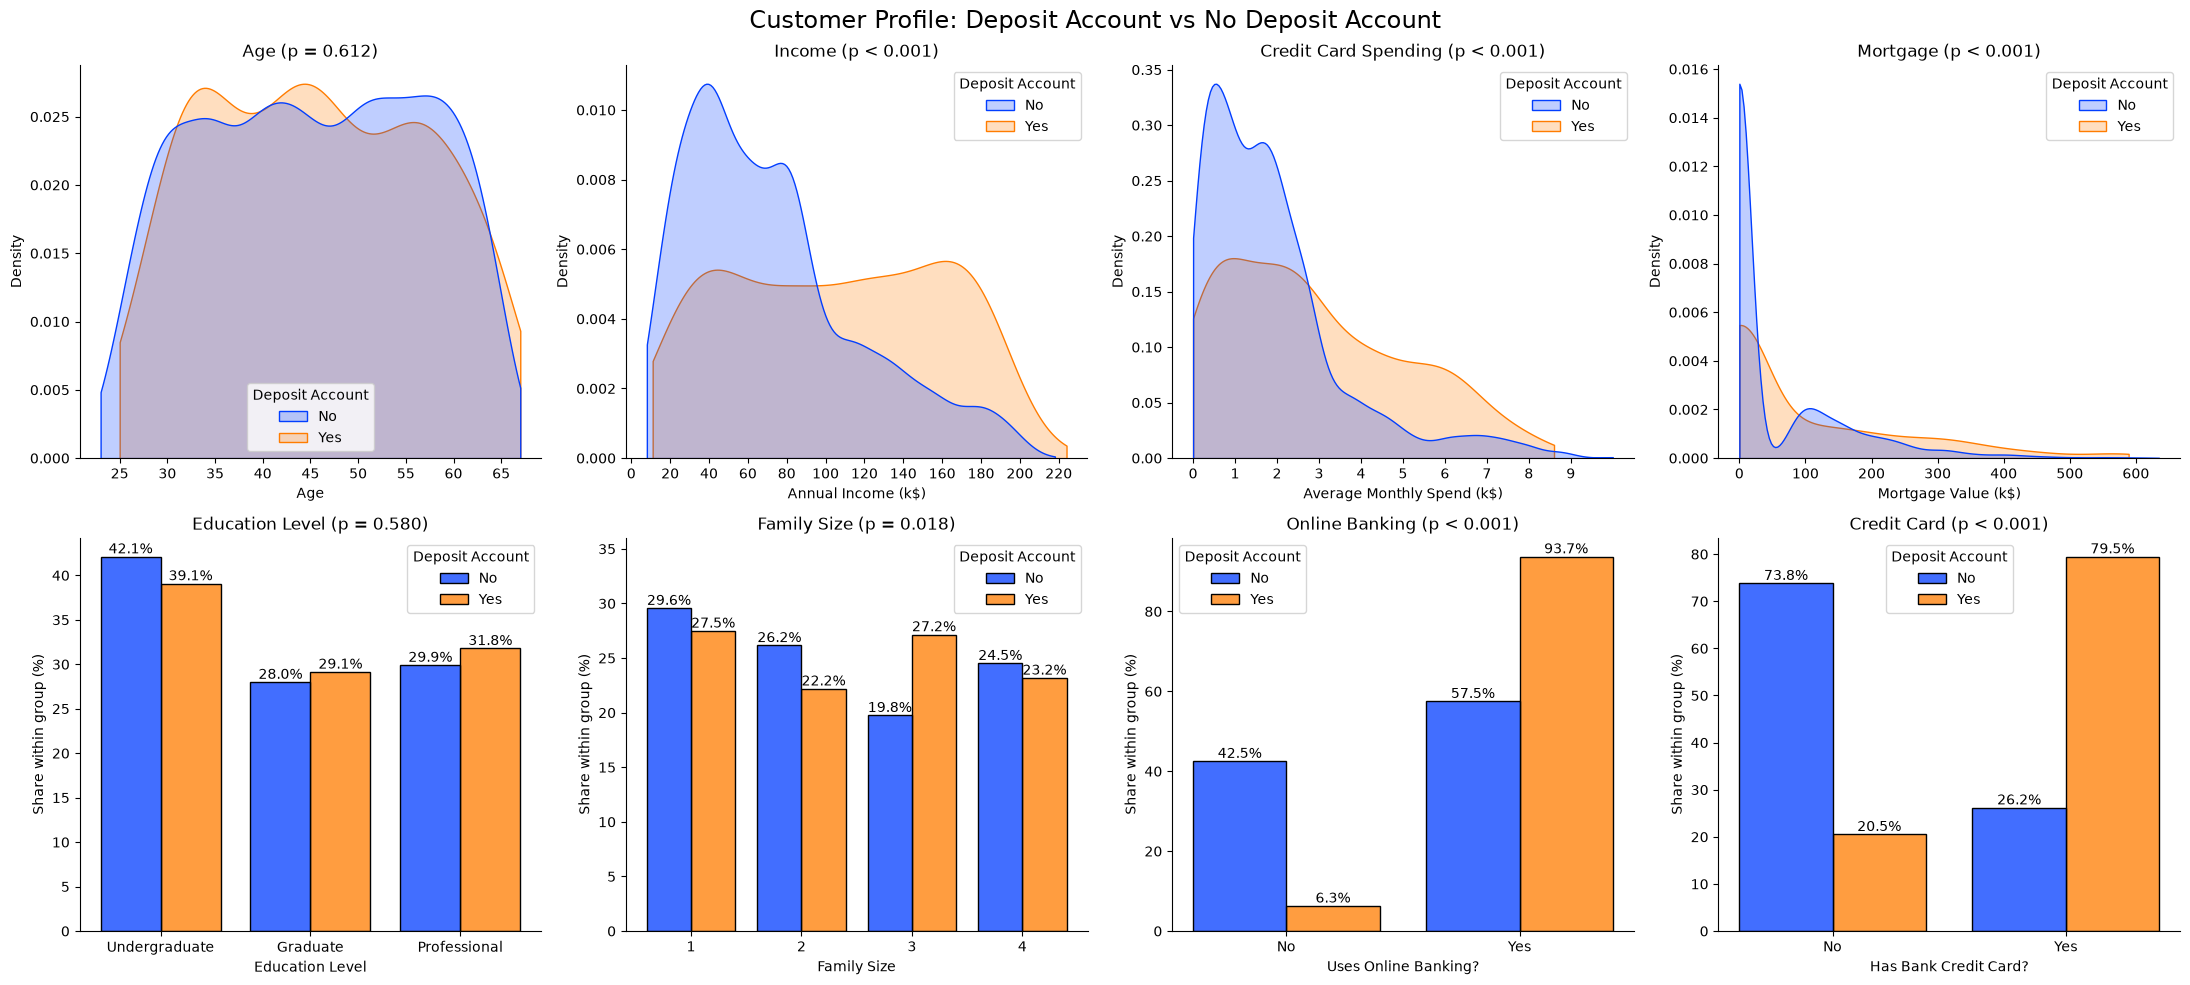

In [64]:
# Panel plot (2x4)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

# Row 1: Continuous variables
## Plot 1: Age
sns.kdeplot(
    data=data_plot,
    x="Age",
    hue="Deposit Account",
    fill=True,
    common_norm=False,
    cut=0,
    ax=axes[0]
)
axes[0].set(
    title="Age (p = 0.612)",
    xlabel="Age",
    ylabel="Density",
    xticks=np.arange(25, data["Age"].max(), 5)
)

## Plot 2: Income
sns.kdeplot(
    data=data_plot,
    x="Income",
    hue="Deposit Account",
    fill=True,
    common_norm=False,
    cut=0,
    ax=axes[1]
)
axes[1].set(
    title="Income (p < 0.001)",
    xlabel="Annual Income (k$)",
    ylabel="Density",
    xticks=np.arange(0, data["Income"].max(), 20)
)

## Plot 3: Average Credit Card Spending
sns.kdeplot(
    data=data_plot,
    x="CCAvg",
    hue="Deposit Account",
    fill=True,
    common_norm=False,
    cut=0,
    ax=axes[2],
)
axes[2].set(
    title="Credit Card Spending (p < 0.001)",
    xlabel="Average Monthly Spend (k$)",
    ylabel="Density",
    xticks=np.arange(0, data["CCAvg"].max()),
)

## Plot 4: House Mortgage Value
sns.kdeplot(
    data=data_plot,
    x="Mortgage",
    hue="Deposit Account",
    fill=True,
    common_norm=False,
    cut=0,
    ax=axes[3],
)
axes[3].set(
    title="Mortgage (p < 0.001)",
    xlabel="Mortgage Value (k$)",
    ylabel="Density",
    xticks=np.arange(0, data["Mortgage"].max(), 100)
)

# Row 2: Categorical variables
## Plot 5: Education
sns.histplot(
    data=data_plot,
    x="Education",
    hue="Deposit Account",
    multiple="dodge",
    stat="percent",
    common_norm=False,
    discrete=True,
    shrink=0.8,
    ax=axes[4],
)
label_bars(axes[4])
axes[4].set(
    title="Education Level (p = 0.580)",
    xlabel="Education Level",
    ylabel="Share within group (%)",
    xticks=[1, 2, 3],
    xticklabels=["Undergraduate", "Graduate", "Professional"],
)

## Plot 6: Family Size
sns.histplot(
    data=data_plot,
    x="Family",
    hue="Deposit Account",
    multiple="dodge",
    stat="percent",
    common_norm=False,
    discrete=True,
    shrink=0.8,
    ax=axes[5],
)
label_bars(axes[5])
axes[5].set(
    title="Family Size (p = 0.018)",
    xlabel="Family Size",
    ylabel="Share within group (%)",
    xticks=[1, 2, 3, 4],
    ylim=(0, 36)
)

## Plot 7: Online Banking
sns.histplot(
    data=data_plot, 
    x="Online Facilities", 
    hue="Deposit Account",
    multiple="dodge", 
    stat="percent", 
    common_norm=False,
    shrink=0.8, ax=axes[6]
)
label_bars(axes[6])
axes[6].set(
    title="Online Banking (p < 0.001)",
    xlabel="Uses Online Banking?",
    ylabel="Share within group (%)"
)

## Plot 8: Credit Card
sns.histplot(
    data=data_plot,
    x="Credit Card",
    hue="Deposit Account",
    multiple="dodge",
    stat="percent",
    common_norm=False,
    shrink=0.8, 
    ax=axes[7]
)
label_bars(axes[7])
axes[7].set(
    title="Credit Card (p < 0.001)",
    xlabel="Has Bank Credit Card?", 
    ylabel="Share within group (%)"
)

plt.suptitle("Customer Profile: Deposit Account vs No Deposit Account", fontsize=17)
sns.despine()
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q5.svg", bbox_inches="tight")
plt.show()

**Interpretation:** Compared to Securities Account holders who don't differ much, deposit account holders vary substantially compared to those who don't have this product. They have a much higher income, with a median of 107 k$ compared to 62k$ without one, they have higher credit card spending, and higher mortgages. They are also more important users of the other banking products, including online banking and credit card. On the other hand, their education and age are similar to that of the rest of the customers.

### Question 6: How many customers have one account only? How many have multiple accounts (i.e., both security and CD accounts)?

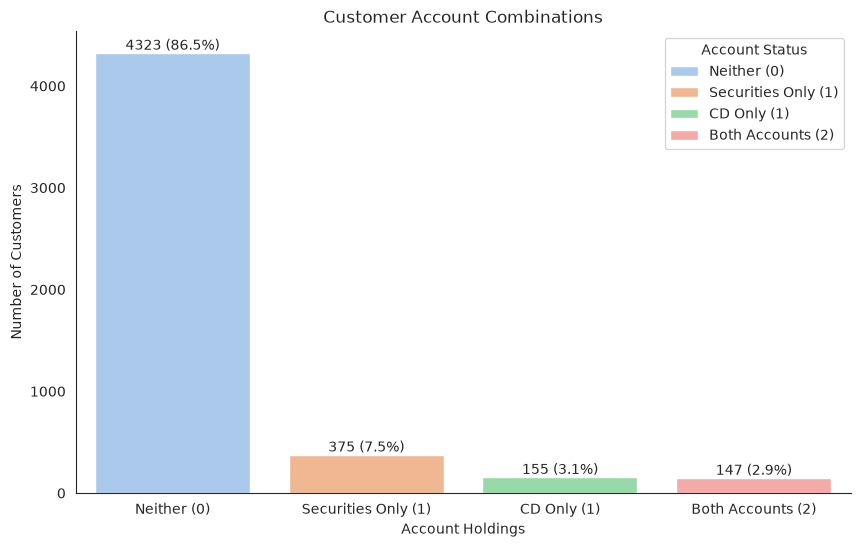

In [220]:
# Creating a label for each combination of Securities Account and Certificate of Deposit Account
df_q6 = data.copy()

conditions = [(df_q6['Securities Account'] == 0) & (df_q6['Certificate of Deposit Account'] == 0),
              (df_q6['Securities Account'] == 1) & (df_q6['Certificate of Deposit Account'] == 0),
              (df_q6['Securities Account'] == 0) & (df_q6['Certificate of Deposit Account'] == 1),
              (df_q6['Securities Account'] == 1) & (df_q6['Certificate of Deposit Account'] == 1)]
choices = ['Neither (0)', 'Securities Only (1)', 'CD Only (1)', 'Both Accounts (2)']
df_q6['Account_Status'] = np.select(conditions, choices, default='Unknown')

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
order = ['Neither (0)', 'Securities Only (1)', 'CD Only (1)', 'Both Accounts (2)'] # Condition ordering
sns.countplot(data=df_q6, x='Account_Status', hue='Account_Status', hue_order=order, order=order,
              legend=True, ax=ax)
ax.set(title='Customer Account Combinations', xlabel='Account Holdings', ylabel='Number of Customers')
ax.legend(title='Account Status')

# Counts and percentages on top of the bars
total_customers = len(df_q6)
for container in ax.containers:
    labels = [f'{int(bar.get_height())} ({(bar.get_height() / total_customers * 100):.1f}%)' 
              for bar in container] 
    ax.bar_label(container, labels=labels)
sns.despine()
plt.show()

### Question 7: What are the most important factors that lead to customers responding favorably to the marketing campaign?

In [221]:
# Pearson Correlation with Personal Loan
# As said above, we drop Experience since it's perfectly correlated with Age
corr_loan = data.corr(numeric_only=True)['Personal Loan'].drop(labels=['Personal Loan', 'ID', 'ZIP Code', 'Experience']).sort_values(ascending=False)
display(corr_loan.to_frame().round(3))

,Personal Loan
Income,0.502
CCAvg,0.367
Certificate of Deposit Account,0.316
Mortgage,0.142
Education,0.137
Family,0.061
Securities Account,0.022
Online Facilities,0.006
Credit Card,0.003
Age,-0.008


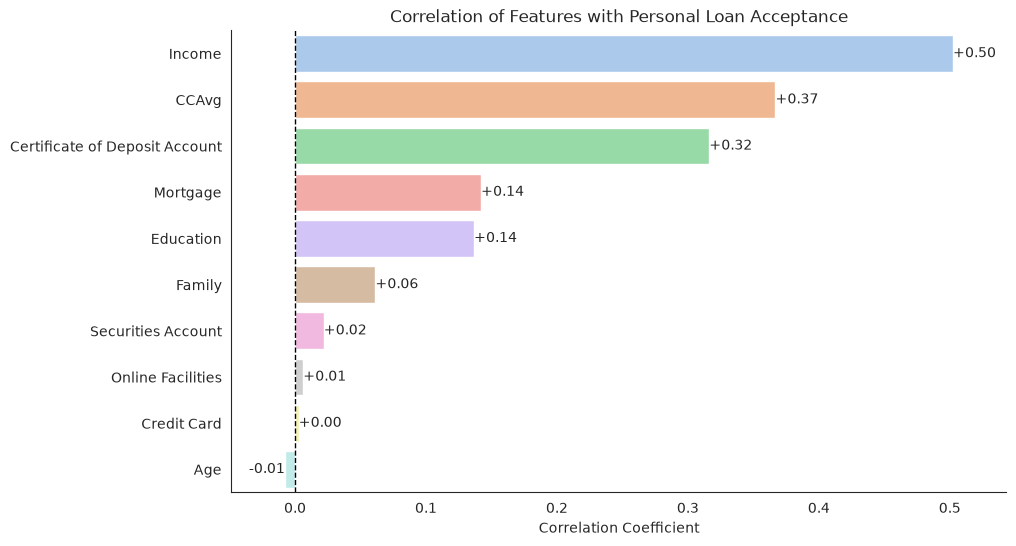

In [222]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=corr_loan.values, y=corr_loan.index, hue=corr_loan.index, ax=ax)
ax.set(title='Correlation of Features with Personal Loan Acceptance', 
       xlabel='Correlation Coefficient', 
       ylabel=None)
ax.axvline(x=0, color='black', linewidth=1, linestyle='--')
for container in ax.containers:
    ax.bar_label(container, fmt='%+.2f') 
ax.margins(x=0.08) # X-axis margin for percentage labels
sns.despine()
plt.show()

In [ ]:
## Logit regression 


### Question 8: Build a simple machine learning classification model that predicts, based on a customer's features, if they will respond to the marketing campaign or not.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
features = ["Age", "Income", "Family", "CCAvg", "Education", "Mortgage",
            "Securities Account", "Certificate of Deposit Account", "Online Facilities", "Credit Card"]
y = data["Personal Loan"]
X = data[features]
## Tree
# We use grid search and trainsplits; most of the code is re-used from our Machine Learning class with Pr Rossi.
from sklearn import model_selection
X_tv, X_test, Y_tv, Y_test = model_selection.train_test_split(
X, y, test_size = 0.2, stratify = y, random_state=0)
from sklearn.model_selection import StratifiedShuffleSplit
v_split = StratifiedShuffleSplit(n_splits=4, train_size=0.75, random_state=0) 

algorithm_params = {
    'min_samples_split': [2, 10, 20, 40, 60, 80, 100, 150, 200, 300],
    'max_depth': list(range(2, 6, 2)),
    'min_impurity_decrease': np.linspace(0, 0.005, 11),
}

from sklearn.model_selection import GridSearchCV
grid_search_rmse = GridSearchCV(DecisionTreeClassifier(random_state = 0),algorithm_params, cv = v_split)

grid_search_rmse = grid_search_rmse.fit(X_tv, Y_tv)

In [233]:
results = pd.DataFrame(grid_search_rmse.cv_results_)
results[['param_min_samples_split', 'param_max_depth',
         'param_min_impurity_decrease','mean_test_score']].sort_values('mean_test_score', ascending= False).head(10)

,param_min_samples_split,param_max_depth,param_min_impurity_decrease,mean_test_score
243,40,None,0.0010,0.98775
233,40,None,0.0005,0.98775
223,40,None,0.0000,0.98775
242,20,None,0.0010,0.98725
240,2,None,0.0010,0.98700
241,10,None,0.0010,0.98700
253,40,None,0.0015,0.98675
250,2,None,0.0015,0.98675
251,10,None,0.0015,0.98675
252,20,None,0.0015,0.98675


[Text(0.5, 0.9, 'Income <= 113.5\ngini = 0.174\nsamples = 4000\nvalue = [3616, 384]'),
 Text(0.2631578947368421, 0.7, 'CCAvg <= 2.95\ngini = 0.042\nsamples = 3229\nvalue = [3159, 70]'),
 Text(0.381578947368421, 0.8, 'True  '),
 Text(0.10526315789473684, 0.5, 'Income <= 106.5\ngini = 0.007\nsamples = 2982\nvalue = [2972, 10]'),
 Text(0.05263157894736842, 0.3, 'gini = 0.0\nsamples = 2907\nvalue = [2907, 0]'),
 Text(0.15789473684210525, 0.3, 'Family <= 3.5\ngini = 0.231\nsamples = 75\nvalue = [65, 10]'),
 Text(0.10526315789473684, 0.1, '\n  (...)  \n'),
 Text(0.21052631578947367, 0.1, '\n  (...)  \n'),
 Text(0.42105263157894735, 0.5, 'Certificate of Deposit Account <= 0.5\ngini = 0.368\nsamples = 247\nvalue = [187, 60]'),
 Text(0.3684210526315789, 0.3, 'Income <= 92.5\ngini = 0.31\nsamples = 224\nvalue = [181, 43]'),
 Text(0.3157894736842105, 0.1, '\n  (...)  \n'),
 Text(0.42105263157894735, 0.1, '\n  (...)  \n'),
 Text(0.47368421052631576, 0.3, 'gini = 0.386\nsamples = 23\nvalue = [6, 17

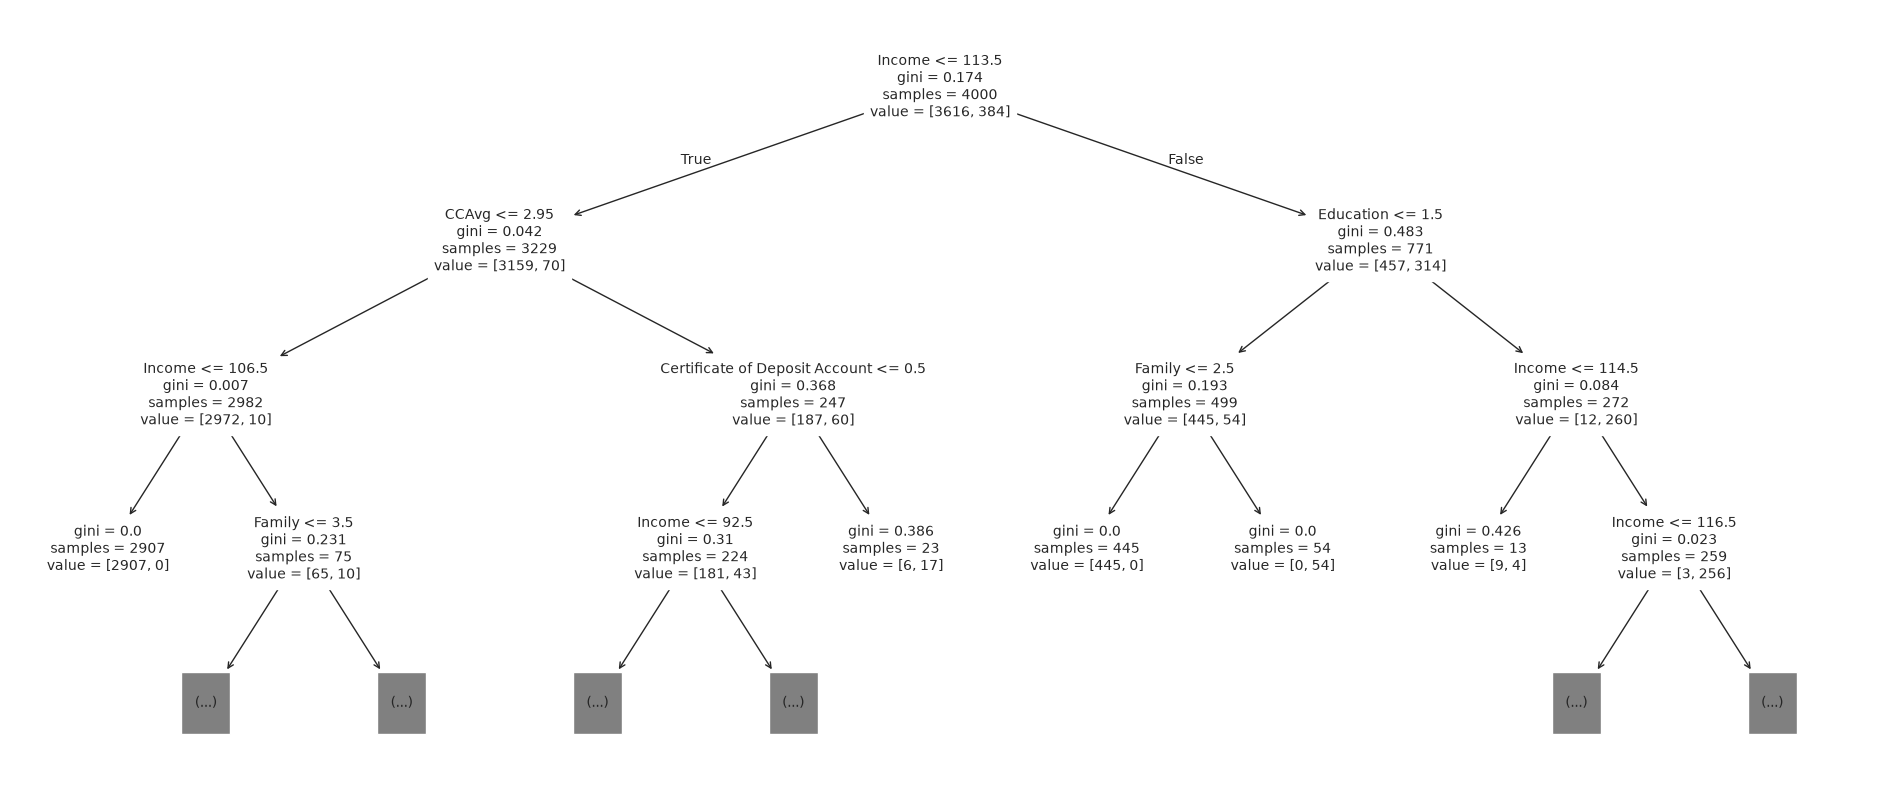

In [234]:
from sklearn.tree import plot_tree
fig, ax = plt.subplots(figsize=(24, 10))

best = grid_search_rmse.best_estimator_
plot_tree(best, feature_names= X.columns, ax = ax, max_depth= 3, fontsize = 10)

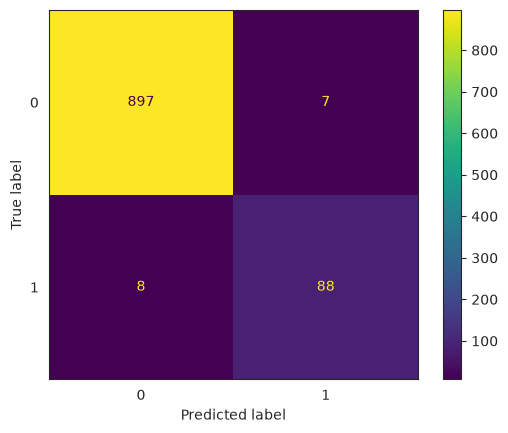

In [235]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(best,X_test, Y_test)